# Traffic forecasting — model report

This notebook opens with **one model's recorded evaluation**. The default is **Timestral-5M with calendar features, forecasting flow and occupancy jointly**. These are real historical backtest results; the final submission model will be chosen in issue #32.

| Sections | What you get |
|---|---|
| **1–5: selected model** | Model settings, evaluation dates, its own error statistics, data coverage, prediction sources and an example forecast. |
| **6: optional comparison** | Compare the already-evaluated models on the same dataset. |
| **7: optional fresh run** | Run the selected model again and save new scores and hourly predictions. |

**Start:** choose the project's `.venv` kernel and run all cells. Sections 1–4 read the saved experiment journal. Section 5 uses local prediction files when available. Both optional controls start at `False`.


## 1. Which model am I looking at?

Change `MODEL_RUN` to inspect another recorded experiment. The default report uses the joint 5M Timestral run. The settings below control the report, comparisons and fresh inference separately.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Open from the repository root or notebooks folder."

MODEL_RUN = "timestral_5m_calendar_multivariate"
SNAPSHOT = "9e714afe6479d9a22e680b0e70893e06fd04c574219a2ec28f9ceffb237c391d"
WINDOW_CUTOFF = "2026-10-22"
EXAMPLE_ROAD = "Convention"
ARTIFACT_DIR = ROOT / "outputs/metrics/timestral_20261101"

SHOW_COMPARISONS = False
RERUN_MODEL = False


In [2]:
MODEL_NAMES = {
    "baseline_previous_week": "Previous-week baseline",
    "baseline_four_week": "Four-week mean baseline",
    "baseline_day_type": "Day-type profile baseline",
    "baseline_holiday_aware": "Holiday-aware baseline",
    "chronos_history": "Chronos-2 — traffic history",
    "chronos_calendar": "Chronos-2 — history + calendar",
    "chronos_retained_multivariate": "Chronos-2 — history + calendar, joint targets",
    "timestral_5m_history": "Timestral-5M — traffic history",
    "timestral_5m_calendar": "Timestral-5M — history + calendar",
    "timestral_5m_calendar_multivariate": "Timestral-5M — history + calendar, joint targets",
    "timestral_28m_calendar": "Timestral-28M — history + calendar",
    "timestral_28m_calendar_multivariate": "Timestral-28M — history + calendar, joint targets",
}
TARGET_NAMES = {"debit_horaire": "Traffic flow", "taux_occupation": "Occupancy"}
TARGET_UNITS = {"debit_horaire": "vehicles/hour", "taux_occupation": "percentage points"}

journal = pd.read_csv(ROOT / "docs/experiments.csv")
recorded = journal.loc[journal.description.str.startswith("Issue #20;", na=False)].copy()
recorded["fingerprint"] = recorded.description.str.extract(r"fingerprint\s+([0-9a-f]{64})", expand=False)
recorded = recorded.loc[recorded.fingerprint.eq(SNAPSHOT)]
recorded["run"] = recorded.description.str.extract(r"Issue #20;\s*([^;]+);", expand=False)
recorded = recorded.drop_duplicates("run", keep="last")
assert MODEL_RUN in set(recorded.run), f"Choose a recorded run from {list(recorded.run)}"
selected_record = recorded.set_index("run").loc[MODEL_RUN]
all_scores = pd.concat([
    pd.DataFrame(json.loads(row.scores)["scores"]).assign(run=row.run)
    for row in recorded.itertuples(index=False)
], ignore_index=True)
all_scores["cutoff"] = pd.to_datetime(all_scores.cutoff)
model_scores = all_scores.loc[all_scores.run.eq(MODEL_RUN)].copy()
window_dates = pd.DatetimeIndex(model_scores.cutoff.unique()).sort_values()
window = pd.Timestamp(WINDOW_CUTOFF)
assert window in window_dates, "Choose a cutoff listed in section 2."
is_foundation = selected_record.model in {"TimestralForecaster", "Chronos2Forecaster"}

def summarize_scores(frame, groups):
    """Pool squared errors over valid observations; retain missing-truth counts."""
    frame = frame.assign(squared_error=frame.rmse.pow(2) * frame.n_scored)
    result = frame.groupby([*groups, "variable"], sort=False).agg(
        squared_error=("squared_error", "sum"),
        expected=("n_expected", "sum"), scored=("n_scored", "sum"), ignored=("n_ignored", "sum"),
    ).reset_index()
    result["rmse"] = np.sqrt(result.squared_error / result.scored.replace(0, np.nan))
    result["coverage"] = 100 * result.scored / result.expected.replace(0, np.nan)
    return result

def score_table(frame, groups=()):
    """Friendly display only: raw scores keep numerical NaN for unscored groups."""
    result = frame[[*groups, "variable", "rmse", "scored", "ignored", "coverage"]].copy()
    result["variable"] = result.variable.map(TARGET_NAMES)
    result["Unit"] = frame.variable.map(TARGET_UNITS)
    result["rmse"] = result.rmse.map(lambda value: "Not scored" if pd.isna(value) else f"{value:.3f}")
    result["coverage"] = result.coverage.round(1)
    result["Status"] = np.where(result.scored.eq(0), "No valid measurements", "Scored")
    return result.rename(columns={
        "arc": "Road", "variable": "Target", "rmse": "RMSE",
        "scored": "Scored hours", "ignored": "Unscored hours",
        "coverage": "Coverage (%)",
    })

def saved_seconds(description, field):
    match = re.search(rf"{field}\s+([0-9.]+)s", description)
    return float(match.group(1)) if match else None


In [3]:
context = re.search(r"context\s+([0-9]+)\s+h", selected_record.description)
settings = {
    "Selected model": MODEL_NAMES.get(MODEL_RUN, MODEL_RUN),
    "Model type": "Pretrained forecasting model" if is_foundation else "Rule-based baseline",
    "Inputs": "Past traffic + calendar" if "calendar" in MODEL_RUN else "Past traffic and rule-specific calendar use",
    "Targets": ("Flow and occupancy jointly" if "multivariate" in MODEL_RUN else
                "Flow and occupancy separately") if is_foundation else "Flow and occupancy",
    "Maximum history": f"{int(context.group(1)):,} hours" if context else "Defined by the baseline rule",
    "Recorded at (UTC)": selected_record.date,
    "Dataset": SNAPSHOT[:8],
    "View": "Saved evaluation results",
}
display(pd.DataFrame(settings.items(), columns=["Setting", "Value"]))


,Setting,Value
0,Selected model,"Timestral-5M — history + calendar, joint targets"
1,Model type,Pretrained forecasting model
2,Inputs,Past traffic + calendar
3,Targets,Flow and occupancy jointly
4,Maximum history,"8,192 hours"
5,Recorded at (UTC),2026-11-01T15:32:36.336328+00:00
6,Dataset,9e714afe
7,View,Saved evaluation results


## 2. How was this model evaluated?

We replay **eight historical forecasting situations**. For each one:

1. The model receives observations through **Thursday 23:00**.
2. It forecasts **144 hours**: Friday plus Saturday–Wednesday.
3. The **120 Saturday–Wednesday hours per road** are scored against valid measurements.

The three official roads are Champs-Elysées, Convention and Saint-Pères. Missing or invalid truth is excluded and counted. The dataset covers January 2024–October 30, 2026. These historical evaluations support the model choice for the November 7–11 submission.


In [4]:
evaluation_windows = pd.DataFrame({
    "History available through": window_dates + pd.Timedelta(hours=23),
    "Forecast begins (Friday)": window_dates + pd.Timedelta(days=1),
    "Scoring begins (Saturday)": window_dates + pd.Timedelta(days=2),
    "Scoring ends (Wednesday)": window_dates + pd.Timedelta(days=6, hours=23),
    "Scored hours per road": 120,
})
for column in evaluation_windows.columns[:-1]:
    evaluation_windows[column] = evaluation_windows[column].dt.strftime("%Y-%m-%d %H:%M")
display(evaluation_windows)


,History available through,Forecast begins (Friday),Scoring begins (Saturday),Scoring ends (Wednesday),Scored hours per road
0,2024-11-07 23:00,2024-11-08 00:00,2024-11-09 00:00,2024-11-13 23:00,120
1,2024-12-19 23:00,2024-12-20 00:00,2024-12-21 00:00,2024-12-25 23:00,120
2,2024-12-26 23:00,2024-12-27 00:00,2024-12-28 00:00,2025-01-01 23:00,120
3,2025-04-17 23:00,2025-04-18 00:00,2025-04-19 00:00,2025-04-23 23:00,120
4,2025-07-10 23:00,2025-07-11 00:00,2025-07-12 00:00,2025-07-16 23:00,120
5,2025-10-16 23:00,2025-10-17 00:00,2025-10-18 00:00,2025-10-22 23:00,120
6,2025-11-06 23:00,2025-11-07 00:00,2025-11-08 00:00,2025-11-12 23:00,120
7,2026-10-22 23:00,2026-10-23 00:00,2026-10-24 00:00,2026-10-28 23:00,120


## 3. The selected model's own statistics

**This section reports only the selected model, across all three official roads.** Its documented baseline fallback is included when sensors provide insufficient recent history.

- **RMSE:** prediction error; lower is better. Flow uses vehicles/hour, occupancy uses percentage points.
- **Scored hours:** road/hour observations with valid ground truth.
- **Unscored hours:** predictions that could not be scored.
- **Coverage:** the fraction of expected observations that could be scored.

RMSE is pooled over valid observations: `sqrt(sum(n_scored × RMSE²) / sum(n_scored))`. The second table isolates weekends and public holidays.


In [5]:
overall = summarize_scores(model_scores.loc[model_scores.subset.eq("all")], [])
print(MODEL_NAMES.get(MODEL_RUN, MODEL_RUN))
print("All scored hours — three official roads")
display(score_table(overall))

atypical = summarize_scores(model_scores.loc[model_scores.subset.eq("atypical")], [])
print("Weekends and public holidays only — three official roads")
display(score_table(atypical))

elapsed = saved_seconds(selected_record.description, "backtest")
loading = saved_seconds(selected_record.description, "loading")
if elapsed is not None:
    print(f"Recorded evaluation time: {elapsed:.1f} seconds for all {len(window_dates)} windows.")
if loading is not None:
    print(f"Weight loading, measured separately: {loading:.3f} seconds.")


Timestral-5M — history + calendar, joint targets
All scored hours — three official roads


,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Traffic flow,143.061,1684,1196,58.5,vehicles/hour,Scored
1,Occupancy,3.872,1684,1196,58.5,percentage points,Scored


Weekends and public holidays only — three official roads


,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Traffic flow,156.210,972,612,61.4,vehicles/hour,Scored
1,Occupancy,4.050,972,612,61.4,percentage points,Scored


Recorded evaluation time: 12.7 seconds for all 8 windows.
Weight loading, measured separately: 0.347 seconds.


## 4. Where does the model make errors?

The first table groups the selected model's errors by road across all eight windows. The next table inspects the window chosen with `WINDOW_CUTOFF`.

**“Not scored” means there were no valid measurements to assess that row.** The model can still have produced forecasts; they are shown in section 5. A missing score is kept separate from a zero error.


In [6]:
per_road = summarize_scores(model_scores.loc[model_scores.subset.eq("all")], ["arc"])
display(score_table(per_road, ["arc"]))

window_scores = model_scores.loc[model_scores.cutoff.eq(window) & model_scores.subset.eq("all")]
window_report = summarize_scores(window_scores, ["arc"])
print(f"Selected window: cutoff {window:%Y-%m-%d}; scored {(window + pd.Timedelta(days=2)):%Y-%m-%d} "
      f"through {(window + pd.Timedelta(days=6)):%Y-%m-%d}")
display(score_table(window_report, ["arc"]))


,Road,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Champs-Elysées,Traffic flow,189.586,690,270,71.9,vehicles/hour,Scored
1,Champs-Elysées,Occupancy,5.653,690,270,71.9,percentage points,Scored
2,Convention,Traffic flow,94.195,659,301,68.6,vehicles/hour,Scored
3,Convention,Occupancy,1.658,659,301,68.6,percentage points,Scored
4,Saint-Pères,Traffic flow,106.755,335,625,34.9,vehicles/hour,Scored
5,Saint-Pères,Occupancy,2.037,335,625,34.9,percentage points,Scored


Selected window: cutoff 2026-10-22; scored 2026-10-24 through 2026-10-28


,Road,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Champs-Elysées,Traffic flow,Not scored,0,120,0.0,vehicles/hour,No valid measurements
1,Champs-Elysées,Occupancy,Not scored,0,120,0.0,percentage points,No valid measurements
2,Convention,Traffic flow,67.601,97,23,80.8,vehicles/hour,Scored
3,Convention,Occupancy,0.793,97,23,80.8,percentage points,Scored
4,Saint-Pères,Traffic flow,143.106,96,24,80.0,vehicles/hour,Scored
5,Saint-Pères,Occupancy,2.505,96,24,80.0,percentage points,Scored


## 5. What did the model actually predict?

This section reads the saved hourly predictions for the selected run. It shows:

- how many forecasts came from the pretrained model and how many used a baseline fallback;
- a short example for `EXAMPLE_ROAD` in the selected window;
- observed and forecast traffic curves when the matching local dataset is available.

A foundation model uses the holiday-aware baseline when an arc has fewer than 168 valid hours in the retained context's last 28 days. The scores above include this mixture. Local prediction files, raw data and weights are kept outside Git; scores remain readable if those files are absent.


In [7]:
predictions = pd.DataFrame()
prediction_path = ARTIFACT_DIR / f"{MODEL_RUN}_predictions.parquet"
manifest_path = ARTIFACT_DIR / "dataset_manifest.json"
if prediction_path.exists() and manifest_path.exists():
    artifact_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if artifact_manifest["fingerprint"] == SNAPSHOT:
        predictions = pd.read_parquet(prediction_path)
    else:
        print("Choose an artifact folder with the selected dataset fingerprint.")
else:
    print("Local prediction files are absent. Scores above remain available from the journal.")

if not predictions.empty:
    print(f"{len(predictions):,} forecasts across {predictions.cutoff.nunique()} windows.")
    if is_foundation:
        origins = np.where(predictions.forecast_source.str.startswith("fallback_"),
                           "Baseline fallback", "Pretrained model")
    else:
        origins = pd.Series("Baseline rules", index=predictions.index)
    source_counts = pd.crosstab(predictions.arc, origins).rename_axis(index="Road", columns=None)
    source_counts["Total forecast hours"] = source_counts.sum(axis=1)
    display(source_counts)


2,880 forecasts across 8 windows.


,Baseline fallback,Pretrained model,Total forecast hours
Road,,,
Champs-Elysées,120,840,960
Convention,240,720,960
Saint-Pères,600,360,960


In [8]:
example = pd.DataFrame()
has_observations = False
if not predictions.empty:
    example = predictions.loc[
        predictions.cutoff.eq(window) & predictions.arc.eq(EXAMPLE_ROAD)
    ].sort_values("datetime").copy()
    assert not example.empty, "Choose a road present in the saved forecasts."
    data_dir = ROOT / "data/processed/dataset"
    if (data_dir / "dataset.parquet").exists() and (data_dir / "_manifest.json").exists():
        local_manifest = json.loads((data_dir / "_manifest.json").read_text(encoding="utf-8"))
        if local_manifest["fingerprint"] == SNAPSHOT:
            from traffic_prediction.data.dataset import content_sha256

            observations = pd.read_parquet(data_dir / "dataset.parquet")
            assert content_sha256(observations) == local_manifest["content_sha256"]["dataset.parquet"], "Dataset changed."
            observations = observations.loc[
                observations.arc.eq(EXAMPLE_ROAD),
                ["datetime", "debit_horaire", "taux_occupation", "qualite_mesure"],
            ].copy()
            observations.loc[observations.qualite_mesure.ne("ok"),
                             ["debit_horaire", "taux_occupation"]] = np.nan
            observations = observations.rename(columns={
                "debit_horaire": "actual_flow", "taux_occupation": "actual_occupancy",
            })
            example = example.merge(observations, on="datetime", how="left", validate="one_to_one")
            has_observations = True
    columns = ["datetime", "debit_horaire", "taux_occupation"]
    if has_observations:
        columns += ["actual_flow", "actual_occupancy"]
    columns += ["forecast_source"]
    preview = example[columns].head(10).round(3).rename(columns={
        "datetime": "Hour", "debit_horaire": "Predicted flow (veh/h)",
        "taux_occupation": "Predicted occupancy (%)", "actual_flow": "Observed flow (veh/h)",
        "actual_occupancy": "Observed occupancy (%)", "forecast_source": "Prediction source",
    })
    preview = preview.astype(object).where(preview.notna(), "Missing measurement")
    print(f"{EXAMPLE_ROAD} — selected historical window")
    display(preview)
    if not has_observations:
        print("Observed values require the matching local dataset.")


Convention — selected historical window


,Hour,Predicted flow (veh/h),Predicted occupancy (%),Observed flow (veh/h),Observed occupancy (%),Prediction source
0,2026-10-24 00:00:00,382.418,2.57,366.0,2.318,timestral
1,2026-10-24 01:00:00,313.113,2.03,326.0,2.332,timestral
2,2026-10-24 02:00:00,218.431,1.274,214.0,1.435,timestral
3,2026-10-24 03:00:00,175.53,0.985,177.0,1.279,timestral
4,2026-10-24 04:00:00,140.245,0.703,141.0,1.067,timestral
5,2026-10-24 05:00:00,138.289,0.715,125.0,1.557,timestral
6,2026-10-24 06:00:00,139.449,0.763,123.0,0.802,timestral
7,2026-10-24 07:00:00,161.105,1.083,170.0,1.353,timestral
8,2026-10-24 08:00:00,207.953,1.505,197.0,1.722,timestral
9,2026-10-24 09:00:00,317.15,2.284,277.0,2.116,timestral


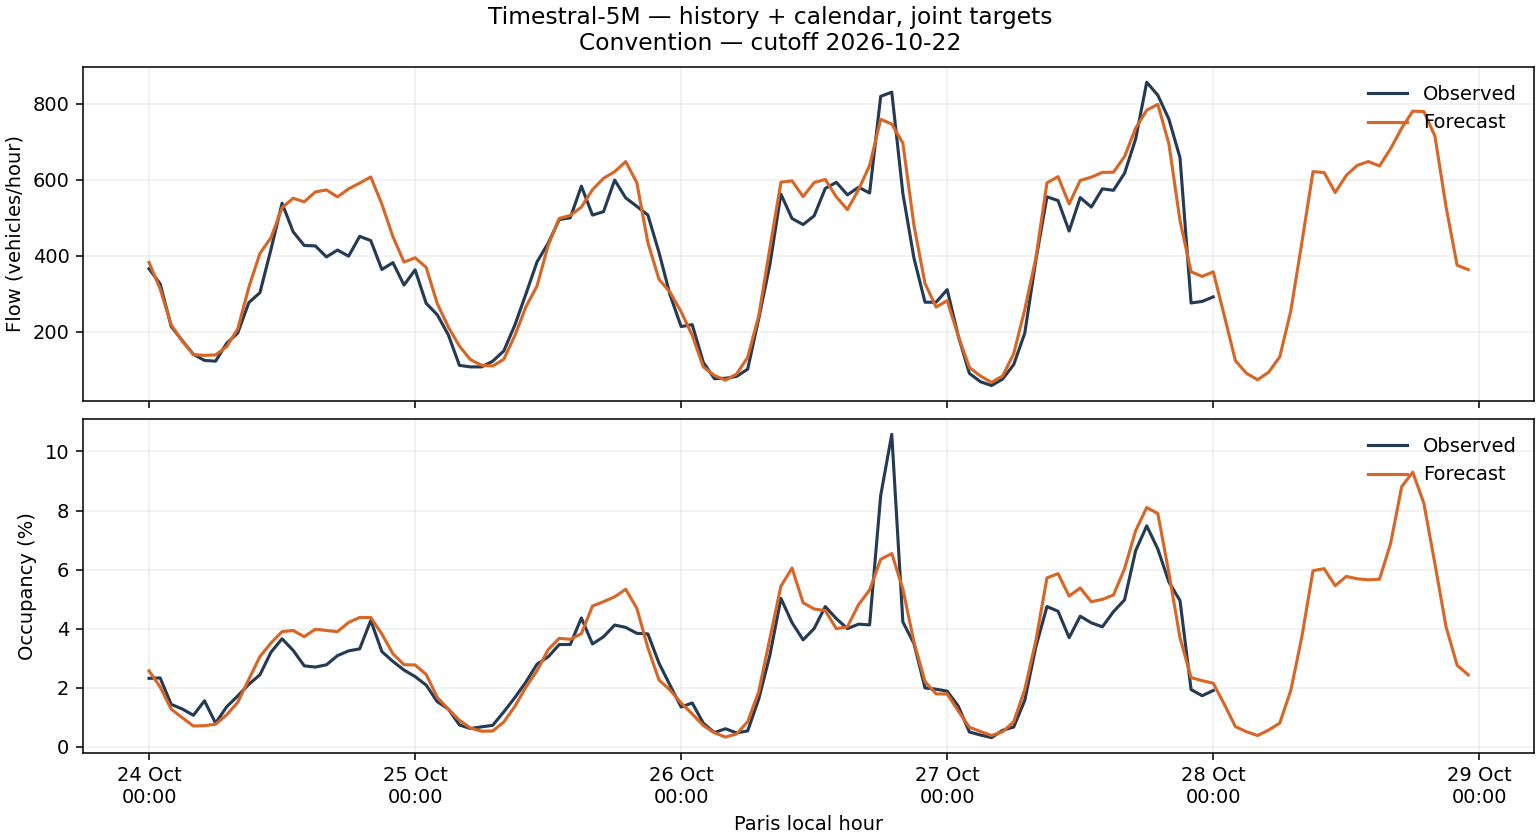

Gaps in the observed curve represent unscored measurements.


In [9]:
if not example.empty and has_observations:
    import importlib.util

    if importlib.util.find_spec("matplotlib") is not None:
        import matplotlib.dates as mdates
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout="constrained")
        for axis, predicted, actual, unit in [
            (axes[0], "debit_horaire", "actual_flow", "Flow (vehicles/hour)"),
            (axes[1], "taux_occupation", "actual_occupancy", "Occupancy (%)"),
        ]:
            if example[actual].notna().any():
                axis.plot(example.datetime, example[actual], color="#243b53", label="Observed", linewidth=1.6)
            axis.plot(example.datetime, example[predicted], color="#d86626", label="Forecast", linewidth=1.6)
            axis.set_ylabel(unit)
            axis.grid(alpha=0.2)
            axis.legend(loc="upper right", frameon=False)
        axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
        axes[1].set_xlabel("Paris local hour")
        fig.suptitle(f"{MODEL_NAMES.get(MODEL_RUN, MODEL_RUN)}\n{EXAMPLE_ROAD} — cutoff {window:%Y-%m-%d}")
        figure_path = ROOT / "outputs/figures" / f"{MODEL_RUN}_{EXAMPLE_ROAD}_{window:%Y%m%d}.png"
        figure_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_path, dpi=140, facecolor="white")
        plt.close(fig)
        display(Image(filename=str(figure_path)))
        if example[["actual_flow", "actual_occupancy"]].notna().any().any():
            print("Gaps in the observed curve represent unscored measurements.")
        else:
            print("This window has no valid observations; the plot shows the saved forecasts.")
    else:
        print("The optional plot uses the Matplotlib version in requirements.txt.")


## 6. Optional: compare this model with the others

Set `SHOW_COMPARISONS = True` in section 1 to display the twelve saved experiments on this same dataset. This reads recorded scores and launches no inference.

The table covers **all three official roads**. It reports flow and occupancy separately; there is no combined ranking across their different units. This comparison supports the final model/ensemble decision in #32.


In [10]:
if SHOW_COMPARISONS:
    cutoff_sets = all_scores.groupby("run").cutoff.agg(lambda values: frozenset(values))
    assert cutoff_sets.nunique() == 1, "Compare runs with matching evaluation windows."
    comparison_scores = summarize_scores(all_scores.loc[all_scores.subset.eq("all")], ["run"])
    comparison_table = comparison_scores.pivot(index="run", columns="variable", values="rmse").rename(
        columns={"debit_horaire": "Flow RMSE (veh/h)", "taux_occupation": "Occupancy RMSE (points)"}
    )
    comparison_table.index = comparison_table.index.map(lambda label: MODEL_NAMES.get(label, label))
    comparison_table.index.name = "Model"
    display(comparison_table.round(3))
else:
    print(f"{len(recorded)} evaluated runs are available. This view focuses on the selected model.")


12 evaluated runs are available. This view focuses on the selected model.


## 7. Optional: run this model again

Set `RERUN_MODEL = True` in section 1 to rerun **only `MODEL_RUN`** on the current local dataset and the shared backtest windows. A pretrained model performs fresh inference; it does not train a new network here.

Prepare local data, dependencies and cached weights using the README first. This step runs offline, creates a new dated folder, saves scores and hourly forecasts, and appends the experiment to `docs/experiments.csv`. The helper cell below is collapsed because it implements saving rather than interpreting results.

After a fresh run, keep `RERUN_MODEL = False` when reading reports. If the dataset changed, use the newly printed fingerprint as `SNAPSHOT` to inspect that saved run in sections 1–6.


In [11]:
def run_and_save(label, model, data, manifest, output_dir, journal_path, author=None):
    """Record scores and aligned hourly forecasts from the common backtest."""
    import getpass
    import time
    from traffic_prediction import evaluate

    records = []
    original_predict = model.predict

    def capture(history, target_times):
        table = original_predict(history, target_times)
        saved = table.copy()
        saved.insert(0, "cutoff", history.datetime.max().normalize())
        trace = getattr(model, "sources_", None)
        if trace is not None:
            index = pd.MultiIndex.from_frame(table[evaluate.KEYS])
            saved["forecast_source"] = trace.reindex(index).to_numpy()
        records.append(saved)
        return table

    loading = 0.0
    if hasattr(model, "_pipeline"):
        started = time.perf_counter()
        model._pipeline()
        loading = time.perf_counter() - started
    cutoffs = evaluate.load_cutoffs()
    model.predict = capture
    started = time.perf_counter()
    try:
        result = evaluate.backtest(model, data, cutoffs, experiments_path=None)
    finally:
        del model.predict
    elapsed = time.perf_counter() - started

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    pd.concat(records, ignore_index=True).to_parquet(
        output_dir / f"{label}_predictions.parquet", index=False, compression="zstd"
    )
    for name in ["scores", "per_arc", "summary"]:
        getattr(result, name).to_csv(output_dir / f"{label}_{name}.csv", index=False)
    settings = model.describe() if hasattr(model, "describe") else type(model).__name__
    metadata = {
        "run": label, "model": type(model).__name__, "settings": settings,
        "dataset_fingerprint": manifest["fingerprint"],
        "cutoffs": [str(day.date()) for day in cutoffs],
        "loading_seconds": loading, "backtest_seconds": elapsed,
    }
    (output_dir / f"{label}_run.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    description = (
        f"Issue #20; {label}; {settings}; fingerprint {manifest['fingerprint']}; "
        f"{len(cutoffs)} shared cutoffs; loading {loading:.3f}s; backtest {elapsed:.3f}s; "
        f"hourly predictions: {output_dir.name}/{label}_predictions.parquet"
    )
    evaluate._append_experiment(result, Path(journal_path), author or getpass.getuser(), type(model).__name__, description)
    return result


In [12]:
if RERUN_MODEL:
    import os
    import platform
    import subprocess
    import sys
    from datetime import datetime, timezone

    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_HUB_CACHE"] = str(ROOT / "models/huggingface")
    os.environ["HF_HOME"] = str(ROOT / "models/hf-home")
    torch_version, torch_threads, cuda_available = None, None, False
    if is_foundation:
        import torch

        torch.set_num_threads(min(6, torch.get_num_threads()))
        torch_version = torch.__version__
        torch_threads = torch.get_num_threads()
        cuda_available = torch.cuda.is_available()
    from traffic_prediction.data.dataset import content_sha256
    from traffic_prediction.data.traffic import file_sha256
    from traffic_prediction.models.baselines import (
        PreviousWeekBaseline, FourWeekMeanBaseline,
        DayTypeProfileBaseline, HolidayAwarePreviousWeekBaseline,
    )
    from traffic_prediction.models.chronos import Chronos2Forecaster
    from traffic_prediction.models.timestral import TimestralForecaster

    dataset_dir = ROOT / "data/processed/dataset"
    manifest = json.loads((dataset_dir / "_manifest.json").read_text(encoding="utf-8"))
    data = pd.read_parquet(dataset_dir / "dataset.parquet")
    calendar_path = ROOT / "data/processed/calendar/calendar.parquet"
    calendar = pd.read_parquet(calendar_path)
    assert content_sha256(data) == manifest["content_sha256"]["dataset.parquet"], "Dataset changed."
    assert file_sha256(calendar_path) == manifest["inputs_sha256"]["calendar"], "Calendar changed."

    factories = {
        "baseline_previous_week": lambda: PreviousWeekBaseline(calendar),
        "baseline_four_week": lambda: FourWeekMeanBaseline(calendar),
        "baseline_day_type": lambda: DayTypeProfileBaseline(calendar),
        "baseline_holiday_aware": lambda: HolidayAwarePreviousWeekBaseline(calendar),
        "chronos_history": lambda: Chronos2Forecaster(calendar, calendar_covariates=(), multivariate=False),
        "chronos_calendar": lambda: Chronos2Forecaster(calendar, multivariate=False),
        "chronos_retained_multivariate": lambda: Chronos2Forecaster(calendar),
        "timestral_5m_history": lambda: TimestralForecaster(calendar, calendar_covariates=()),
        "timestral_5m_calendar": lambda: TimestralForecaster(calendar),
        "timestral_5m_calendar_multivariate": lambda: TimestralForecaster(calendar, multivariate=True),
        "timestral_28m_calendar": lambda: TimestralForecaster(calendar, model_size="28M"),
        "timestral_28m_calendar_multivariate": lambda: TimestralForecaster(calendar, model_size="28M", multivariate=True),
    }
    assert MODEL_RUN in factories, "Choose a configured model from factories."
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output_dir = ROOT / "outputs/metrics" / f"foundation_{timestamp}"
    output_dir.mkdir(parents=True, exist_ok=False)
    (output_dir / "environment.txt").write_text(
        subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8"
    )
    (output_dir / "dataset_manifest.json").write_text(
        json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
    )
    runtime = {"python": platform.python_version(), "platform": platform.platform(),
               "torch": torch_version, "torch_threads": torch_threads,
               "cuda_available": cuda_available}
    (output_dir / "runtime.json").write_text(
        json.dumps(runtime, indent=2) + "\n", encoding="utf-8"
    )
    print({"output": str(output_dir), **runtime})
    result = run_and_save(MODEL_RUN, factories[MODEL_RUN](), data, manifest, output_dir,
                          ROOT / "docs/experiments.csv")
    print("Fresh run saved for:", MODEL_NAMES.get(MODEL_RUN, MODEL_RUN))
    print("Dataset fingerprint:", manifest["fingerprint"])
    fresh = result.scores.loc[result.scores.subset.eq("all")]
    display(score_table(summarize_scores(fresh, [])))
else:
    print("Fresh inference is off. Sections 1–5 show the model evaluation already performed and saved.")


Fresh inference is off. Sections 1–5 show the model evaluation already performed and saved.


## Where are the results kept?

| File | Use |
|---|---|
| `docs/experiments.csv` | Shared, versioned scores, settings, timings and dataset fingerprints. |
| `outputs/metrics/timestral_20261101/` | Local original scores, hourly predictions, weight/environment verification and audit. |
| `outputs/metrics/foundation_<timestamp>/` | Outputs from a fresh run in section 7. |
| `outputs/figures/` | Exportable observed-versus-forecast plots. |

Keep scores and this notebook in Git. Keep raw data, weights and generated evaluation artifacts outside Git; share the small evaluation bundle separately when the team needs the hourly predictions for ensembles.
